In [2]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

PyTorch version: 2.14.0+cpu
CUDA available: False
Using device: cpu


In [3]:
PROJECT_ROOT = Path("..").resolve()

IMAGE_DIR = PROJECT_ROOT / "data" / "external" / "kaggle_dr" / "images"
LABEL_FILE = PROJECT_ROOT / "data" / "external" / "kaggle_dr" / "trainLabels.csv"

MODEL_DIR = PROJECT_ROOT / "models"

RESULT_DIR = (
    PROJECT_ROOT /
    "reports" /
    "external_evaluation"
)

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESNET_PATH = (
    MODEL_DIR /
    "best_resnet18_weighted_extended.pth"
)

BEST_JOINT_PATH = (
    MODEL_DIR /
    "best_joint_finetuned_attention_fusion.pth"
)

LAST_JOINT_PATH = (
    MODEL_DIR /
    "last_joint_finetuned_attention_fusion.pth"
)

print("IMAGE_DIR:", IMAGE_DIR)
print("LABEL_FILE:", LABEL_FILE)
print("MODEL_DIR:", MODEL_DIR)
print("RESULT_DIR:", RESULT_DIR)

IMAGE_DIR: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\kaggle_dr\images
LABEL_FILE: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\kaggle_dr\trainLabels.csv
MODEL_DIR: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models
RESULT_DIR: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\reports\external_evaluation


In [5]:
print("\nChecking files...\n")

print(
    "Images folder exists:",
    IMAGE_DIR.exists()
)

print(
    "Labels file exists:",
    LABEL_FILE.exists()
)

print(
    "ResNet checkpoint exists:",
    RESNET_PATH.exists()
)

print(
    "Best Joint checkpoint exists:",
    BEST_JOINT_PATH.exists()
)

print(
    "Last Joint checkpoint exists:",
    LAST_JOINT_PATH.exists()
)


Checking files...

Images folder exists: True
Labels file exists: True
ResNet checkpoint exists: True
Best Joint checkpoint exists: True
Last Joint checkpoint exists: True


In [6]:
labels_df = pd.read_csv(LABEL_FILE)

print("Number of labels:", len(labels_df))

print("\nColumns:")
print(labels_df.columns.tolist())

print("\nFirst 10 rows:")
display(labels_df.head(10))

print("\nClass distribution:")
print(
    labels_df["level"]
    .value_counts()
    .sort_index()
)

Number of labels: 35126

Columns:
['image', 'level']

First 10 rows:


,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1
5,15_right,2
6,16_left,4
7,16_right,4
8,17_left,0
9,17_right,1



Class distribution:
level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64


In [7]:
image_files = sorted(
    list(IMAGE_DIR.glob("*.jpeg")) +
    list(IMAGE_DIR.glob("*.jpg")) +
    list(IMAGE_DIR.glob("*.png"))
)

print("Images found:", len(image_files))

for p in image_files:
    print(p.name)

Images found: 10
10_left.jpeg
10_right.jpeg
13_left.jpeg
13_right.jpeg
15_left.jpeg
15_right.jpeg
16_left.jpeg
16_right.jpeg
17_left.jpeg
17_right.jpeg


In [8]:
image_df = pd.DataFrame({
    "image": [p.stem for p in image_files],
    "path": [str(p) for p in image_files]
})

external_df = image_df.merge(
    labels_df,
    on="image",
    how="inner"
)

print("Images found:", len(image_df))
print("Images successfully matched with labels:", len(external_df))

display(external_df)

Images found: 10
Images successfully matched with labels: 10


,image,path,level
0,10_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
1,10_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
2,13_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
3,13_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
4,15_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,1
5,15_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,2
6,16_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,4
7,16_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,4
8,17_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
9,17_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,1


In [9]:
print("Number of samples:", len(external_df))

missing_classes = sorted(
    set(range(5)) -
    set(external_df["level"].unique())
)

print("Missing classes:", missing_classes)

Number of samples: 10
Missing classes: [3]


In [10]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [11]:
class ExternalDRDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["path"]
        label = int(row["level"])

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label, row["image"]

In [12]:
external_dataset = ExternalDRDataset(
    external_df,
    transform=eval_transform
)

external_loader = DataLoader(
    external_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Dataset size:", len(external_dataset))
print("Number of batches:", len(external_loader))

Dataset size: 10
Number of batches: 1


In [13]:
def build_resnet18():

    model = models.resnet18(
        weights=None
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        5
    )

    return model

In [14]:
resnet_model = build_resnet18()

resnet_checkpoint = torch.load(
    RESNET_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(resnet_checkpoint))

if isinstance(resnet_checkpoint, dict):

    print("\nCheckpoint keys:")
    print(
        list(resnet_checkpoint.keys())
    )

    resnet_state = resnet_checkpoint[
        "model_state_dict"
    ]

else:

    resnet_state = resnet_checkpoint

resnet_model.load_state_dict(
    resnet_state,
    strict=True
)

resnet_model = resnet_model.to(device)
resnet_model.eval()

print("\n✓ Weighted ResNet-18 loaded successfully")

PermissionError: [Errno 13] Permission denied: 'D:\\downloads\\project\\Diabetic-Retinopathy-Screening-Project\\models\\best_resnet18_weighted_extended.pth'

In [15]:
from pathlib import Path

print("RESNET_PATH:")
print(RESNET_PATH)

print("\nExists:", RESNET_PATH.exists())
print("Is file:", RESNET_PATH.is_file())
print("Is directory:", RESNET_PATH.is_dir())

print("\nModels directory contents:")
for item in MODEL_DIR.iterdir():
    print(
        item.name,
        "| file =", item.is_file(),
        "| directory =", item.is_dir()
    )

RESNET_PATH:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_resnet18_weighted_extended.pth

Exists: True
Is file: False
Is directory: True

Models directory contents:
best_joint_finetuned_attention_fusion.pth | file = False | directory = True
best_resnet18_weighted_extended.pth | file = False | directory = True
last_joint_finetuned_attention_fusion.pth | file = False | directory = True


In [16]:
from pathlib import Path

p = Path(
    r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_resnet18_weighted_extended.pth"
)

print("Exists:", p.exists())
print("Is directory:", p.is_dir())

print("\nContents:")
for x in p.iterdir():
    print(" ", x.name, "DIR" if x.is_dir() else "FILE")

Exists: True
Is directory: True

Contents:
  best_resnet18_weighted_extended DIR


In [17]:
from pathlib import Path
import shutil
import zipfile
import os

PROJECT_ROOT = Path(r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project")
MODEL_DIR = PROJECT_ROOT / "models"

# Current extracted checkpoint folders
checkpoint_folders = {
    "best_resnet18_weighted_extended": 
        MODEL_DIR / "best_resnet18_weighted_extended.pth" / "best_resnet18_weighted_extended",

    "best_joint_finetuned_attention_fusion":
        MODEL_DIR / "best_joint_finetuned_attention_fusion.pth" / "best_joint_finetuned_attention_fusion",

    "last_joint_finetuned_attention_fusion":
        MODEL_DIR / "last_joint_finetuned_attention_fusion.pth" / "last_joint_finetuned_attention_fusion",
}

TEMP_DIR = PROJECT_ROOT / "temp_checkpoints"
TEMP_DIR.mkdir(exist_ok=True)

print("Checkpoint folders:")
for name, path in checkpoint_folders.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())
    print("Is directory:", path.is_dir())

Checkpoint folders:

best_resnet18_weighted_extended
Path: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_resnet18_weighted_extended.pth\best_resnet18_weighted_extended
Exists: True
Is directory: True

best_joint_finetuned_attention_fusion
Path: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\best_joint_finetuned_attention_fusion.pth\best_joint_finetuned_attention_fusion
Exists: True
Is directory: True

last_joint_finetuned_attention_fusion
Path: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\models\last_joint_finetuned_attention_fusion.pth\last_joint_finetuned_attention_fusion
Exists: True
Is directory: True


In [18]:
def rebuild_pth_from_folder(source_dir, output_pth):
    """
    Reconstruct a PyTorch .pth archive from its extracted contents.
    """

    source_dir = Path(source_dir)
    output_pth = Path(output_pth)

    if not source_dir.exists():
        raise FileNotFoundError(
            f"Source folder not found: {source_dir}"
        )

    # Remove existing output if present
    if output_pth.exists():
        if output_pth.is_file():
            output_pth.unlink()
        else:
            raise RuntimeError(
                f"Output path already exists as a directory: {output_pth}"
            )

    with zipfile.ZipFile(
        output_pth,
        mode="w",
        compression=zipfile.ZIP_STORED
    ) as zf:

        for file_path in source_dir.rglob("*"):

            if file_path.is_file():

                relative_path = file_path.relative_to(source_dir)

                zf.write(
                    file_path,
                    arcname=relative_path
                )

    print(
        f"Created: {output_pth}"
        f" ({output_pth.stat().st_size / (1024**2):.2f} MB)"
    )


# Create reconstructed checkpoints in a temporary directory
for name, source_dir in checkpoint_folders.items():

    output_file = (
        TEMP_DIR /
        f"{name}.pth"
    )

    rebuild_pth_from_folder(
        source_dir,
        output_file
    )

Created: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth (128.03 MB)
Created: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_joint_finetuned_attention_fusion.pth (152.92 MB)
Created: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\last_joint_finetuned_attention_fusion.pth (152.93 MB)


In [19]:
import torch

for pth_file in TEMP_DIR.glob("*.pth"):

    print("\n" + "=" * 60)
    print(pth_file.name)
    print("=" * 60)

    print(
        "Size:",
        round(pth_file.stat().st_size / (1024**2), 2),
        "MB"
    )

    try:

        checkpoint = torch.load(
            pth_file,
            map_location="cpu",
            weights_only=False
        )

        print("✓ PyTorch loaded successfully")
        print("Type:", type(checkpoint))

        if isinstance(checkpoint, dict):
            print(
                "Keys:",
                list(checkpoint.keys())
            )

    except Exception as e:

        print("❌ FAILED")
        print(type(e).__name__, ":", e)


best_joint_finetuned_attention_fusion.pth
Size: 152.92 MB
❌ FAILED
RuntimeError : [enforce fail at inline_container.cc:180] . file in archive is not in a subdirectory: .format_version

best_resnet18_weighted_extended.pth
Size: 128.03 MB
❌ FAILED
RuntimeError : [enforce fail at inline_container.cc:180] . file in archive is not in a subdirectory: .format_version

last_joint_finetuned_attention_fusion.pth
Size: 152.93 MB
❌ FAILED
RuntimeError : [enforce fail at inline_container.cc:180] . file in archive is not in a subdirectory: .format_version


In [20]:
from pathlib import Path

for p in TEMP_DIR.glob("*.pth"):
    p.unlink()
    print("Deleted:", p)

print("Temporary checkpoint files cleared.")

Deleted: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_joint_finetuned_attention_fusion.pth
Deleted: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth
Deleted: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\last_joint_finetuned_attention_fusion.pth
Temporary checkpoint files cleared.


In [21]:
import zipfile
from pathlib import Path


def rebuild_pth_from_folder(source_dir, output_pth):
    """
    Reconstruct a PyTorch checkpoint while preserving
    the top-level directory expected by PyTorch.
    """

    source_dir = Path(source_dir)
    output_pth = Path(output_pth)

    if not source_dir.exists():
        raise FileNotFoundError(
            f"Source folder not found: {source_dir}"
        )

    if not source_dir.is_dir():
        raise ValueError(
            f"Source is not a directory: {source_dir}"
        )

    if output_pth.exists():
        output_pth.unlink()

    # IMPORTANT:
    # PyTorch expects files inside a top-level directory.
    root_name = source_dir.name

    with zipfile.ZipFile(
        output_pth,
        mode="w",
        compression=zipfile.ZIP_STORED
    ) as zf:

        for file_path in source_dir.rglob("*"):

            if not file_path.is_file():
                continue

            relative_path = file_path.relative_to(
                source_dir
            )

            archive_path = (
                Path(root_name) /
                relative_path
            )

            zf.write(
                file_path,
                arcname=str(archive_path)
            )

    print(
        f"Created: {output_pth.name}"
    )

    print(
        f"Size: "
        f"{output_pth.stat().st_size / (1024**2):.2f} MB"
    )

In [22]:
for name, source_dir in checkpoint_folders.items():

    output_file = (
        TEMP_DIR /
        f"{name}.pth"
    )

    rebuild_pth_from_folder(
        source_dir,
        output_file
    )

Created: best_resnet18_weighted_extended.pth
Size: 128.05 MB
Created: best_joint_finetuned_attention_fusion.pth
Size: 152.98 MB
Created: last_joint_finetuned_attention_fusion.pth
Size: 152.99 MB


In [23]:
import torch

for pth_file in sorted(TEMP_DIR.glob("*.pth")):

    print("\n" + "=" * 70)
    print(pth_file.name)
    print("=" * 70)

    print(
        "Size:",
        round(
            pth_file.stat().st_size / (1024**2),
            2
        ),
        "MB"
    )

    try:

        checkpoint = torch.load(
            pth_file,
            map_location="cpu",
            weights_only=False
        )

        print("✓ PyTorch loaded successfully")
        print(
            "Type:",
            type(checkpoint)
        )

        if isinstance(checkpoint, dict):

            print(
                "Checkpoint keys:"
            )

            print(
                list(checkpoint.keys())
            )

    except Exception as e:

        print("❌ FAILED")
        print(
            type(e).__name__,
            ":",
            e
        )


best_joint_finetuned_attention_fusion.pth
Size: 152.98 MB
✓ PyTorch loaded successfully
Type: <class 'dict'>
Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history', 'best_val_qwk', 'best_val_loss', 'epochs_no_improve', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_qwk']

best_resnet18_weighted_extended.pth
Size: 128.05 MB
✓ PyTorch loaded successfully
Type: <class 'dict'>
Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'val_loss', 'val_accuracy', 'val_qwk', 'history', 'class_weights']

last_joint_finetuned_attention_fusion.pth
Size: 152.99 MB
✓ PyTorch loaded successfully
Type: <class 'dict'>
Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'history', 'best_val_qwk', 'best_val_loss', 'epochs_no_improve', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_qwk']


In [24]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project paths
PROJECT_ROOT = Path(r"D:\downloads\project\Diabetic-Retinopathy-Screening-Project")

IMAGE_DIR = PROJECT_ROOT / "data" / "external" / "kaggle_dr" / "images"
LABEL_FILE = PROJECT_ROOT / "data" / "external" / "kaggle_dr" / "trainLabels.csv"

MODEL_DIR = PROJECT_ROOT / "models"
TEMP_DIR = PROJECT_ROOT / "temp_checkpoints"

RESULT_DIR = PROJECT_ROOT / "reports" / "external_evaluation"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Images:", IMAGE_DIR)
print("Labels:", LABEL_FILE)
print("Temporary checkpoints:", TEMP_DIR)
print("Results:", RESULT_DIR)

Images: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\kaggle_dr\images
Labels: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\data\external\kaggle_dr\trainLabels.csv
Temporary checkpoints: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints
Results: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\reports\external_evaluation


In [25]:
labels_df = pd.read_csv(LABEL_FILE)

print("Total labeled images in Kaggle trainLabels.csv:", len(labels_df))

print("\nColumns:")
print(labels_df.columns.tolist())

print("\nFirst 5 rows:")
display(labels_df.head())

Total labeled images in Kaggle trainLabels.csv: 35126

Columns:
['image', 'level']

First 5 rows:


,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1


In [26]:
image_files = sorted(
    list(IMAGE_DIR.glob("*.jpeg")) +
    list(IMAGE_DIR.glob("*.jpg")) +
    list(IMAGE_DIR.glob("*.png"))
)

image_df = pd.DataFrame({
    "image": [p.stem for p in image_files],
    "path": [str(p) for p in image_files]
})

external_df = image_df.merge(
    labels_df,
    on="image",
    how="inner"
)

print("Images found:", len(image_df))
print("Images matched with labels:", len(external_df))

display(external_df)

Images found: 10
Images matched with labels: 10


,image,path,level
0,10_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
1,10_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
2,13_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
3,13_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
4,15_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,1
5,15_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,2
6,16_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,4
7,16_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,4
8,17_left,D:\downloads\project\Diabetic-Retinopathy-Scre...,0
9,17_right,D:\downloads\project\Diabetic-Retinopathy-Scre...,1


In [27]:
class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "PDR"
}

class_counts = (
    external_df["level"]
    .value_counts()
    .sort_index()
)

print("External sample class distribution:\n")

for label in range(5):
    count = class_counts.get(label, 0)
    print(
        f"{label} - {class_names[label]:10s}: {count}"
    )

External sample class distribution:

0 - No DR     : 5
1 - Mild      : 2
2 - Moderate  : 1
3 - Severe    : 0
4 - PDR       : 2


In [28]:
from torchvision import transforms

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Evaluation transform ready.")

Evaluation transform ready.


In [29]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader


class ExternalDRDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["path"]
        label = int(row["level"])

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return (
            image,
            label,
            row["image"]
        )

In [30]:
external_dataset = ExternalDRDataset(
    external_df,
    transform=eval_transform
)

external_loader = DataLoader(
    external_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Dataset size:", len(external_dataset))
print("Number of batches:", len(external_loader))

Dataset size: 10
Number of batches: 1


In [31]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


def build_resnet18():

    model = models.resnet18(
        weights=None
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        5
    )

    return model

Using device: cpu


In [32]:
RESNET_TEST_PATH = (
    TEMP_DIR /
    "best_resnet18_weighted_extended.pth"
)

print("Checkpoint:")
print(RESNET_TEST_PATH)

print("\nExists:", RESNET_TEST_PATH.exists())
print("Is file:", RESNET_TEST_PATH.is_file())
print(
    "Size:",
    round(
        RESNET_TEST_PATH.stat().st_size / (1024**2),
        2
    ),
    "MB"
)

Checkpoint:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_resnet18_weighted_extended.pth

Exists: True
Is file: True
Size: 128.05 MB


In [33]:
resnet_checkpoint = torch.load(
    RESNET_TEST_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded.")
print(
    "Checkpoint epoch:",
    resnet_checkpoint.get("epoch")
)

print(
    "Stored validation accuracy:",
    resnet_checkpoint.get("val_accuracy")
)

print(
    "Stored validation QWK:",
    resnet_checkpoint.get("val_qwk")
)

Checkpoint loaded.
Checkpoint epoch: 8
Stored validation accuracy: 0.7897242284963887
Stored validation QWK: 0.7929597067362694


In [34]:
resnet_model = build_resnet18()

resnet_model.load_state_dict(
    resnet_checkpoint["model_state_dict"],
    strict=True
)

resnet_model = resnet_model.to(device)

resnet_model.eval()

print("✓ Weighted ResNet-18 loaded successfully.")

✓ Weighted ResNet-18 loaded successfully.


In [35]:
images, labels, image_ids = next(
    iter(external_loader)
)

images = images.to(device)

with torch.no_grad():

    logits = resnet_model(images)

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    predictions = probabilities.argmax(
        dim=1
    )

print("Input shape:")
print(images.shape)

print("\nLogits shape:")
print(logits.shape)

print("\nProbability shape:")
print(probabilities.shape)

print("\nPredictions:")
print(predictions.cpu().numpy())

print("\nProbability sums:")
print(
    probabilities.sum(dim=1).cpu().numpy()
)

Input shape:
torch.Size([10, 3, 224, 224])

Logits shape:
torch.Size([10, 5])

Probability shape:
torch.Size([10, 5])

Predictions:
[0 0 0 0 0 0 4 4 0 0]

Probability sums:
[1.0000001  0.99999994 1.0000001  0.99999994 0.99999994 1.
 1.         1.         1.         1.        ]


In [36]:
@torch.no_grad()
def predict_resnet(
    model,
    loader,
    device
):

    model.eval()

    all_true = []
    all_pred = []
    all_prob = []
    all_ids = []

    for images, labels, image_ids in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = probabilities.argmax(
            dim=1
        )

        all_true.extend(
            labels.numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

        all_prob.append(
            probabilities.cpu().numpy()
        )

        all_ids.extend(
            image_ids
        )

    return (
        np.array(all_true),
        np.array(all_pred),
        np.concatenate(all_prob),
        all_ids
    )

In [37]:
from tqdm.auto import tqdm

resnet_y_true, resnet_y_pred, resnet_y_prob, resnet_ids = (
    predict_resnet(
        resnet_model,
        external_loader,
        device
    )
)

print("✓ ResNet inference completed.")
print("Number of predictions:", len(resnet_y_pred))

✓ ResNet inference completed.
Number of predictions: 10


In [38]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    log_loss
)


def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    results = {}

    results["Accuracy"] = accuracy_score(
        y_true,
        y_pred
    )

    results["Balanced Accuracy"] = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )

    results["Macro Precision"] = (
        precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Macro Recall"] = (
        recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Macro F1"] = (
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["Weighted F1"] = (
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    results["QWK"] = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    results["Cohen Kappa"] = (
        cohen_kappa_score(
            y_true,
            y_pred
        )
    )

    results["MCC"] = matthews_corrcoef(
        y_true,
        y_pred
    )

    # These require all relevant classes
    try:
        results["ROC-AUC"] = roc_auc_score(
            y_true,
            y_prob,
            multi_class="ovr",
            average="macro",
            labels=[0, 1, 2, 3, 4]
        )
    except ValueError:
        results["ROC-AUC"] = np.nan

    try:
        results["Log Loss"] = log_loss(
            y_true,
            y_prob,
            labels=[0, 1, 2, 3, 4]
        )
    except ValueError:
        results["Log Loss"] = np.nan

    return results

In [39]:
resnet_metrics = calculate_metrics(
    resnet_y_true,
    resnet_y_pred,
    resnet_y_prob
)

print("=" * 65)
print("WEIGHTED RESNET-18 — KAGGLE SAMPLE")
print("=" * 65)

for metric, value in resnet_metrics.items():

    if pd.isna(value):
        print(f"{metric:22s}: N/A")

    else:
        print(
            f"{metric:22s}: {value:.4f}"
        )

WEIGHTED RESNET-18 — KAGGLE SAMPLE
Accuracy              : 0.7000
Balanced Accuracy     : 0.5000
Macro Precision       : 0.4062
Macro Recall          : 0.5000
Macro F1              : 0.4423
Weighted F1           : 0.5846
QWK                   : 0.8000
Cohen Kappa           : 0.4643
MCC                   : 0.5658
ROC-AUC               : N/A
Log Loss              : 1.0240


In [40]:
print(
    classification_report(
        resnet_y_true,
        resnet_y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "PDR"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

       No DR       0.62      1.00      0.77         5
        Mild       0.00      0.00      0.00         2
    Moderate       0.00      0.00      0.00         1
      Severe       0.00      0.00      0.00         0
         PDR       1.00      1.00      1.00         2

    accuracy                           0.70        10
   macro avg       0.33      0.40      0.35        10
weighted avg       0.51      0.70      0.58        10



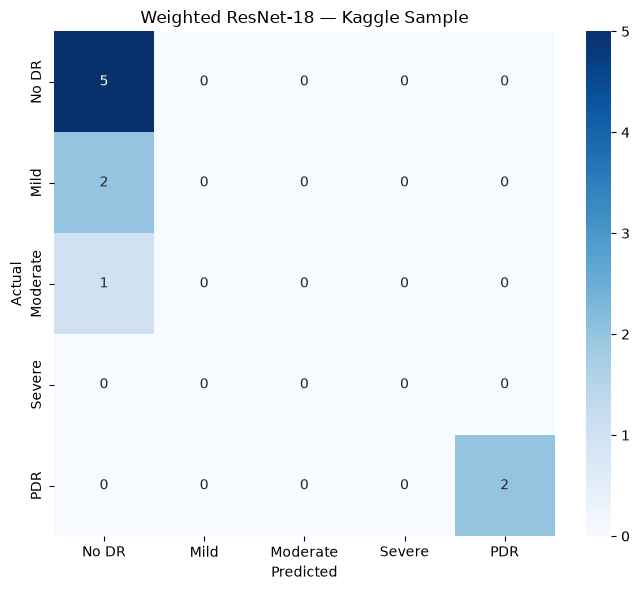

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_resnet = confusion_matrix(
    resnet_y_true,
    resnet_y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "PDR"
    ],
    yticklabels=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "PDR"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    "Weighted ResNet-18 — Kaggle Sample"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR /
    "resnet18_sample_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
resnet_predictions = pd.DataFrame({
    "image": resnet_ids,
    "true_label": resnet_y_true,
    "predicted_label": resnet_y_pred,

    "prob_no_dr": resnet_y_prob[:, 0],
    "prob_mild": resnet_y_prob[:, 1],
    "prob_moderate": resnet_y_prob[:, 2],
    "prob_severe": resnet_y_prob[:, 3],
    "prob_pdr": resnet_y_prob[:, 4],
})

resnet_predictions.to_csv(
    RESULT_DIR /
    "resnet18_sample_predictions.csv",
    index=False
)

display(resnet_predictions)

,image,true_label,predicted_label,prob_no_dr,prob_mild,prob_moderate,prob_severe,prob_pdr
0,10_left,0,0,0.914322,0.065085,0.012802,7.783388e-03,8.395039e-06
1,10_right,0,0,0.534643,0.026994,0.438312,9.019079e-06,4.288792e-05
2,13_left,0,0,0.989744,0.008950,0.001287,1.684106e-05,1.703423e-06
3,13_right,0,0,0.818302,0.179963,0.001734,6.538972e-07,6.936093e-08
4,15_left,1,0,0.901525,0.050172,0.046872,1.424680e-03,6.917491e-06
5,15_right,2,0,0.983854,0.006542,0.009602,1.540652e-06,1.219848e-06
6,16_left,4,4,0.003142,0.000148,0.003728,3.407423e-01,6.522389e-01
7,16_right,4,4,0.006994,0.001976,0.018424,1.869163e-01,7.856894e-01
8,17_left,0,0,0.965899,0.017204,0.016894,3.385018e-07,2.849750e-06
9,17_right,1,0,0.542906,0.378117,0.078940,3.247270e-05,4.125076e-06


In [43]:
class JointAttentionFusionModel(nn.Module):

    def __init__(
        self,
        resnet_features,
        efficientnet_features,
        efficientnet_pool,
        num_classes=5
    ):

        super().__init__()

        self.resnet_features = (
            resnet_features
        )

        self.efficientnet_features = (
            efficientnet_features
        )

        self.efficientnet_pool = (
            efficientnet_pool
        )

        self.resnet_projection = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.efficientnet_projection = nn.Sequential(
            nn.Linear(1280, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256)
        )

        self.attention = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # ResNet branch
        r_feat = self.resnet_features(x)

        r_feat = torch.flatten(
            r_feat,
            1
        )

        r_proj = self.resnet_projection(
            r_feat
        )

        # EfficientNet branch
        e_feat = self.efficientnet_features(x)

        e_feat = self.efficientnet_pool(
            e_feat
        )

        e_feat = torch.flatten(
            e_feat,
            1
        )

        e_proj = self.efficientnet_projection(
            e_feat
        )

        # Attention
        combined = torch.cat(
            [r_proj, e_proj],
            dim=1
        )

        attention_logits = self.attention(
            combined
        )

        attention_weights = torch.softmax(
            attention_logits,
            dim=1
        )

        # Attention-weighted fusion
        fused = (
            attention_weights[:, 0:1] * r_proj
            +
            attention_weights[:, 1:2] * e_proj
        )

        output = self.classifier(
            fused
        )

        return output, attention_weights

In [44]:
# ResNet backbone
resnet_raw = models.resnet18(
    weights=None
)

resnet_raw.fc = nn.Linear(
    resnet_raw.fc.in_features,
    5
)

# EfficientNet backbone
efficientnet_raw = models.efficientnet_b0(
    weights=None
)

efficientnet_raw.classifier[1] = nn.Linear(
    efficientnet_raw.classifier[1].in_features,
    5
)

# Remove classification heads
resnet_features = nn.Sequential(
    *list(resnet_raw.children())[:-1]
)

efficientnet_features = (
    efficientnet_raw.features
)

efficientnet_pool = nn.AdaptiveAvgPool2d(
    (1, 1)
)

print("✓ Backbones created.")

✓ Backbones created.


In [45]:
joint_model = JointAttentionFusionModel(
    resnet_features,
    efficientnet_features,
    efficientnet_pool,
    num_classes=5
)

joint_model = joint_model.to(device)

print("✓ Joint Attention Fusion model created.")

✓ Joint Attention Fusion model created.


In [46]:
BEST_JOINT_TEST_PATH = (
    TEMP_DIR /
    "best_joint_finetuned_attention_fusion.pth"
)

print("Checkpoint:")
print(BEST_JOINT_TEST_PATH)

print("\nExists:", BEST_JOINT_TEST_PATH.exists())
print("Is file:", BEST_JOINT_TEST_PATH.is_file())

print(
    "Size:",
    round(
        BEST_JOINT_TEST_PATH.stat().st_size / (1024**2),
        2
    ),
    "MB"
)

Checkpoint:
D:\downloads\project\Diabetic-Retinopathy-Screening-Project\temp_checkpoints\best_joint_finetuned_attention_fusion.pth

Exists: True
Is file: True
Size: 152.98 MB


In [47]:
best_joint_checkpoint = torch.load(
    BEST_JOINT_TEST_PATH,
    map_location=device,
    weights_only=False
)

print(
    "Checkpoint epoch:",
    best_joint_checkpoint.get("epoch")
)

print(
    "Stored validation accuracy:",
    best_joint_checkpoint.get("val_accuracy")
)

print(
    "Stored validation Macro-F1:",
    best_joint_checkpoint.get("val_macro_f1")
)

print(
    "Stored validation QWK:",
    best_joint_checkpoint.get("val_qwk")
)

Checkpoint epoch: 4
Stored validation accuracy: 0.7534471437951412
Stored validation Macro-F1: 0.6764252654397527
Stored validation QWK: 0.767966557623569


In [48]:
joint_model.load_state_dict(
    best_joint_checkpoint[
        "model_state_dict"
    ],
    strict=True
)

joint_model = joint_model.to(device)

joint_model.eval()

print(
    "✓ BEST Joint Attention Fusion checkpoint loaded successfully."
)

✓ BEST Joint Attention Fusion checkpoint loaded successfully.


In [49]:
images, labels, image_ids = next(
    iter(external_loader)
)

images = images.to(device)

with torch.no_grad():

    logits, attention = joint_model(
        images
    )

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    predictions = probabilities.argmax(
        dim=1
    )

print("Input shape:")
print(images.shape)

print("\nLogits shape:")
print(logits.shape)

print("\nProbability shape:")
print(probabilities.shape)

print("\nAttention shape:")
print(attention.shape)

print("\nPredictions:")
print(
    predictions.cpu().numpy()
)

print("\nAttention weights:")
print(
    attention.cpu().numpy()
)

print("\nAttention sums:")
print(
    attention.sum(dim=1).cpu().numpy()
)

Input shape:
torch.Size([10, 3, 224, 224])

Logits shape:
torch.Size([10, 5])

Probability shape:
torch.Size([10, 5])

Attention shape:
torch.Size([10, 2])

Predictions:
[0 0 0 0 0 0 3 4 0 0]

Attention weights:
[[0.7132367  0.28676334]
 [0.72976637 0.27023363]
 [0.54911757 0.45088238]
 [0.64754516 0.3524549 ]
 [0.694788   0.30521205]
 [0.6170945  0.38290542]
 [0.9084717  0.09152824]
 [0.87649393 0.12350609]
 [0.5760287  0.4239713 ]
 [0.63733244 0.3626675 ]]

Attention sums:
[1.         1.         0.99999994 1.         1.         0.99999994
 0.99999994 1.         1.         0.99999994]


In [50]:
@torch.no_grad()
def predict_joint(
    model,
    loader,
    device
):

    model.eval()

    all_true = []
    all_pred = []
    all_prob = []
    all_attention = []
    all_ids = []

    for images, labels, image_ids in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        logits, attention = model(
            images
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = probabilities.argmax(
            dim=1
        )

        all_true.extend(
            labels.numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

        all_prob.append(
            probabilities.cpu().numpy()
        )

        all_attention.append(
            attention.cpu().numpy()
        )

        all_ids.extend(
            image_ids
        )

    return (
        np.array(all_true),
        np.array(all_pred),
        np.concatenate(all_prob),
        np.concatenate(all_attention),
        all_ids
    )

In [51]:
(
    joint_y_true,
    joint_y_pred,
    joint_y_prob,
    joint_attention,
    joint_ids
) = predict_joint(
    joint_model,
    external_loader,
    device
)

print("✓ Joint inference completed.")
print(
    "Number of predictions:",
    len(joint_y_pred)
)

✓ Joint inference completed.
Number of predictions: 10


In [52]:
joint_metrics = calculate_metrics(
    joint_y_true,
    joint_y_pred,
    joint_y_prob
)

print("=" * 65)
print("BEST JOINT ATTENTION FUSION — KAGGLE SAMPLE")
print("=" * 65)

for metric, value in joint_metrics.items():

    if pd.isna(value):
        print(f"{metric:22s}: N/A")

    else:
        print(
            f"{metric:22s}: {value:.4f}"
        )

BEST JOINT ATTENTION FUSION — KAGGLE SAMPLE
Accuracy              : 0.6000
Balanced Accuracy     : 0.3750
Macro Precision       : 0.3250
Macro Recall          : 0.3000
Macro F1              : 0.2872
Weighted F1           : 0.5179
QWK                   : 0.8485
Cohen Kappa           : 0.3103
MCC                   : 0.3800
ROC-AUC               : N/A
Log Loss              : 0.9661


In [53]:
print(
    classification_report(
        joint_y_true,
        joint_y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "PDR"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

       No DR       0.62      1.00      0.77         5
        Mild       0.00      0.00      0.00         2
    Moderate       0.00      0.00      0.00         1
      Severe       0.00      0.00      0.00         0
         PDR       1.00      0.50      0.67         2

    accuracy                           0.60        10
   macro avg       0.33      0.30      0.29        10
weighted avg       0.51      0.60      0.52        10



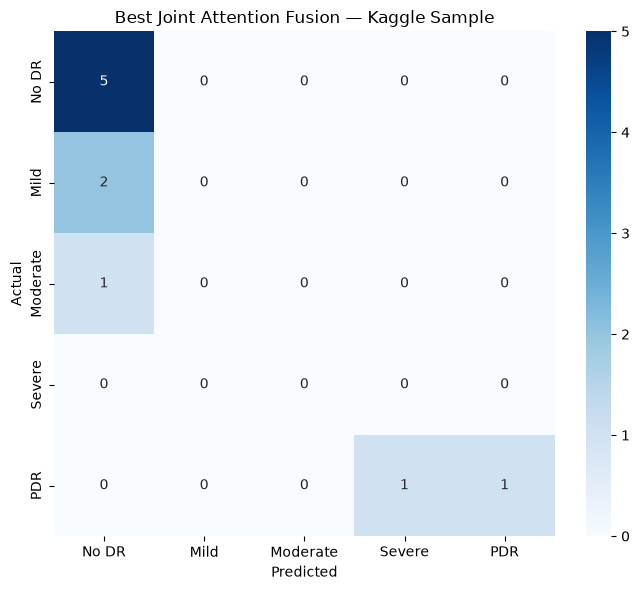

In [54]:
cm_joint = confusion_matrix(
    joint_y_true,
    joint_y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_joint,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "PDR"
    ],
    yticklabels=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "PDR"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(
    "Best Joint Attention Fusion — Kaggle Sample"
)

plt.tight_layout()

plt.savefig(
    RESULT_DIR /
    "joint_attention_sample_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
joint_predictions = pd.DataFrame({

    "image": joint_ids,

    "true_label": joint_y_true,

    "predicted_label": joint_y_pred,

    "prob_no_dr": joint_y_prob[:, 0],

    "prob_mild": joint_y_prob[:, 1],

    "prob_moderate": joint_y_prob[:, 2],

    "prob_severe": joint_y_prob[:, 3],

    "prob_pdr": joint_y_prob[:, 4],

    "resnet_attention": joint_attention[:, 0],

    "efficientnet_attention": joint_attention[:, 1]
})

joint_predictions.to_csv(
    RESULT_DIR /
    "joint_attention_sample_predictions.csv",
    index=False
)

display(joint_predictions)

,image,true_label,predicted_label,prob_no_dr,prob_mild,prob_moderate,prob_severe,prob_pdr,resnet_attention,efficientnet_attention
0,10_left,0,0,0.827730,0.107834,0.055936,0.006413,0.002087,0.713237,0.286763
1,10_right,0,0,0.564325,0.099482,0.324049,0.005526,0.006618,0.729766,0.270234
2,13_left,0,0,0.983777,0.013651,0.002560,0.000006,0.000007,0.549118,0.450882
3,13_right,0,0,0.862131,0.118558,0.018940,0.000210,0.000162,0.647545,0.352455
4,15_left,1,0,0.822516,0.081944,0.082972,0.008583,0.003985,0.694788,0.305212
5,15_right,2,0,0.908527,0.036656,0.054023,0.000310,0.000484,0.617095,0.382905
6,16_left,4,3,0.004644,0.004098,0.034233,0.677066,0.279958,0.908472,0.091528
7,16_right,4,4,0.005220,0.006326,0.047149,0.354744,0.586561,0.876494,0.123506
8,17_left,0,0,0.860602,0.081525,0.056738,0.000440,0.000695,0.576029,0.423971
9,17_right,1,0,0.598661,0.257185,0.137459,0.003763,0.002932,0.637332,0.362668


In [56]:
comparison = pd.DataFrame([
    {
        "Model": "Weighted ResNet-18",
        **resnet_metrics
    },
    {
        "Model": "Best Joint Attention Fusion",
        **joint_metrics
    }
])

display(comparison)

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,QWK,Cohen Kappa,MCC,ROC-AUC,Log Loss
0,Weighted ResNet-18,0.7,0.500,0.40625,0.5,0.442308,0.584615,0.800000,0.464286,0.565752,NaN,1.024046
1,Best Joint Attention Fusion,0.6,0.375,0.32500,0.3,0.287179,0.517949,0.848485,0.310345,0.379980,NaN,0.966065


In [57]:
comparison.to_csv(
    RESULT_DIR /
    "sample_model_comparison.csv",
    index=False
)

print(
    "Saved comparison to:",
    RESULT_DIR /
    "sample_model_comparison.csv"
)

Saved comparison to: D:\downloads\project\Diabetic-Retinopathy-Screening-Project\reports\external_evaluation\sample_model_comparison.csv


In [58]:
prediction_comparison = pd.DataFrame({

    "image": resnet_ids,

    "actual": resnet_y_true,

    "ResNet_prediction": resnet_y_pred,

    "Joint_prediction": joint_y_pred,

    "ResNet_correct": (
        resnet_y_true ==
        resnet_y_pred
    ),

    "Joint_correct": (
        joint_y_true ==
        joint_y_pred
    )
})

display(prediction_comparison)

,image,actual,ResNet_prediction,Joint_prediction,ResNet_correct,Joint_correct
0,10_left,0,0,0,True,True
1,10_right,0,0,0,True,True
2,13_left,0,0,0,True,True
3,13_right,0,0,0,True,True
4,15_left,1,0,0,False,False
5,15_right,2,0,0,False,False
6,16_left,4,4,3,True,False
7,16_right,4,4,4,True,True
8,17_left,0,0,0,True,True
9,17_right,1,0,0,False,False


In [59]:
print("========== RESNET ERRORS ==========")

display(
    prediction_comparison[
        ~prediction_comparison[
            "ResNet_correct"
        ]
    ]
)

print("\n========== JOINT MODEL ERRORS ==========")

display(
    prediction_comparison[
        ~prediction_comparison[
            "Joint_correct"
        ]
    ]
)

========== RESNET ERRORS ==========


,image,actual,ResNet_prediction,Joint_prediction,ResNet_correct,Joint_correct
4,15_left,1,0,0,False,False
5,15_right,2,0,0,False,False
9,17_right,1,0,0,False,False



========== JOINT MODEL ERRORS ==========


,image,actual,ResNet_prediction,Joint_prediction,ResNet_correct,Joint_correct
4,15_left,1,0,0,False,False
5,15_right,2,0,0,False,False
6,16_left,4,4,3,True,False
9,17_right,1,0,0,False,False


In [60]:
attention_df = pd.DataFrame({

    "image": joint_ids,

    "actual": joint_y_true,

    "prediction": joint_y_pred,

    "ResNet_attention": joint_attention[:, 0],

    "EfficientNet_attention": joint_attention[:, 1]
})

display(
    attention_df.sort_values(
        "ResNet_attention"
    )
)

,image,actual,prediction,ResNet_attention,EfficientNet_attention
2,13_left,0,0,0.549118,0.450882
8,17_left,0,0,0.576029,0.423971
5,15_right,2,0,0.617095,0.382905
9,17_right,1,0,0.637332,0.362668
3,13_right,0,0,0.647545,0.352455
4,15_left,1,0,0.694788,0.305212
0,10_left,0,0,0.713237,0.286763
1,10_right,0,0,0.729766,0.270234
7,16_right,4,4,0.876494,0.123506
6,16_left,4,3,0.908472,0.091528


In [61]:
summary = pd.DataFrame({

    "Model": [
        "Weighted ResNet-18",
        "Best Joint Attention Fusion"
    ],

    "Accuracy": [
        resnet_metrics["Accuracy"],
        joint_metrics["Accuracy"]
    ],

    "Balanced Accuracy": [
        resnet_metrics["Balanced Accuracy"],
        joint_metrics["Balanced Accuracy"]
    ],

    "Macro Precision": [
        resnet_metrics["Macro Precision"],
        joint_metrics["Macro Precision"]
    ],

    "Macro Recall": [
        resnet_metrics["Macro Recall"],
        joint_metrics["Macro Recall"]
    ],

    "Macro F1": [
        resnet_metrics["Macro F1"],
        joint_metrics["Macro F1"]
    ],

    "QWK": [
        resnet_metrics["QWK"],
        joint_metrics["QWK"]
    ],

    "MCC": [
        resnet_metrics["MCC"],
        joint_metrics["MCC"]
    ]
})

display(summary)

summary.to_csv(
    RESULT_DIR /
    "external_sample_final_summary.csv",
    index=False
)

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,QWK,MCC
0,Weighted ResNet-18,0.7,0.500,0.40625,0.5,0.442308,0.800000,0.565752
1,Best Joint Attention Fusion,0.6,0.375,0.32500,0.3,0.287179,0.848485,0.379980


In [62]:
print("Files generated:\n")

for file in sorted(RESULT_DIR.iterdir()):
    print(file.name)

Files generated:

external_sample_final_summary.csv
joint_attention_sample_confusion_matrix.png
joint_attention_sample_predictions.csv
resnet18_sample_confusion_matrix.png
resnet18_sample_predictions.csv
sample_model_comparison.csv


In [63]:
display(comparison)

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,QWK,Cohen Kappa,MCC,ROC-AUC,Log Loss
0,Weighted ResNet-18,0.7,0.500,0.40625,0.5,0.442308,0.584615,0.800000,0.464286,0.565752,NaN,1.024046
1,Best Joint Attention Fusion,0.6,0.375,0.32500,0.3,0.287179,0.517949,0.848485,0.310345,0.379980,NaN,0.966065
